In [6]:
# ============================================================
# SMARTVISION AI
# PHASE 4 - MODEL INTEGRATION & PIPELINE DEVELOPMENT
# STEP 4.1 - INFERENCE PIPELINE DESIGN
# CELL 1 - SETUP, IMPORTS & FINAL MODEL PATHS
# ============================================================

from pathlib import Path

import torch
import torch.nn as nn
from torchvision import models, transforms

from PIL import Image
import numpy as np
import cv2
import matplotlib.pyplot as plt

from ultralytics import YOLO


# ------------------------------------------------------------
# PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(r"E:\SmartVision-AI")

YOLO_MODEL_PATH = (
    PROJECT_DIR
    / "runs"
    / "detection"
    / "yolov8s_v2_targeted_15ep"
    / "weights"
    / "best.pt"
)

RESNET_MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "resnet50_final_best.pth"
)

RESULTS_DIR = (
    PROJECT_DIR
    / "results"
    / "integration"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

# Keep integration on CPU for now because CUDA was unstable.
# GPU acceleration will be handled separately in Step 4.3.
DEVICE = torch.device("cpu")


# ------------------------------------------------------------
# VERIFY SETUP
# ------------------------------------------------------------

print("=" * 70)
print("SMARTVISION AI - PHASE 4 INTEGRATION")
print("=" * 70)

print("\nYOLO checkpoint:")
print(YOLO_MODEL_PATH)
print("Exists:", YOLO_MODEL_PATH.exists())

print("\nResNet50 checkpoint:")
print(RESNET_MODEL_PATH)
print("Exists:", RESNET_MODEL_PATH.exists())

print("\nResults directory:")
print(RESULTS_DIR)

print("\nIntegration device:", DEVICE)

assert YOLO_MODEL_PATH.exists(), "YOLO checkpoint not found."
assert RESNET_MODEL_PATH.exists(), "ResNet50 checkpoint not found."

print("\n✅ Phase 4 integration environment ready.")

SMARTVISION AI - PHASE 4 INTEGRATION

YOLO checkpoint:
E:\SmartVision-AI\runs\detection\yolov8s_v2_targeted_15ep\weights\best.pt
Exists: True

ResNet50 checkpoint:
E:\SmartVision-AI\models\resnet50_final_best.pth
Exists: True

Results directory:
E:\SmartVision-AI\results\integration

Integration device: cpu

✅ Phase 4 integration environment ready.


In [7]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 2 - LOAD FINAL YOLO + RESNET50 MODELS
# ============================================================

# ------------------------------------------------------------
# 1. LOAD FINAL YOLO DETECTOR
# ------------------------------------------------------------

print("Loading final YOLOv8s detector...")

yolo_model = YOLO(str(YOLO_MODEL_PATH))

print("✅ YOLOv8s loaded")
print("YOLO classes:", len(yolo_model.names))


# ------------------------------------------------------------
# 2. BUILD FINAL RESNET50 ARCHITECTURE
# ------------------------------------------------------------

print("\nLoading final ResNet50 classifier...")

resnet_model = models.resnet50(weights=None)

resnet_model.fc = nn.Sequential(
    nn.Linear(2048, 512),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(512, 25)
)


# ------------------------------------------------------------
# 3. LOAD RESNET50 CHECKPOINT
# ------------------------------------------------------------

checkpoint = torch.load(
    RESNET_MODEL_PATH,
    map_location=DEVICE,
    weights_only=False
)

# Support either a saved state_dict directly
# or a checkpoint dictionary.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
else:
    state_dict = checkpoint

resnet_model.load_state_dict(state_dict)

resnet_model = resnet_model.to(DEVICE)
resnet_model.eval()


# ------------------------------------------------------------
# VERIFY
# ------------------------------------------------------------

print("✅ ResNet50 loaded")
print("ResNet50 output classes:", resnet_model.fc[-1].out_features)

print("\n" + "=" * 70)
print("FINAL MODELS READY FOR INTEGRATION")
print("=" * 70)

print("Detector   : YOLOv8s")
print("YOLO mAP50 : 80.78%")

print("\nClassifier       : ResNet50")
print("ResNet50 accuracy: 86.13%")

print("\nDevice:", DEVICE)

print("\n✅ Both final models are ready.")

Loading final YOLOv8s detector...
✅ YOLOv8s loaded
YOLO classes: 25

Loading final ResNet50 classifier...
✅ ResNet50 loaded
ResNet50 output classes: 25

FINAL MODELS READY FOR INTEGRATION
Detector   : YOLOv8s
YOLO mAP50 : 80.78%

Classifier       : ResNet50
ResNet50 accuracy: 86.13%

Device: cpu

✅ Both final models are ready.


In [8]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 3 - CLASS MAPPINGS + RESNET PREPROCESSING
# ============================================================

# ------------------------------------------------------------
# YOLO CLASS MAPPING
# ------------------------------------------------------------

YOLO_CLASSES = {
    0: "person",
    1: "bicycle",
    2: "car",
    3: "motorcycle",
    4: "airplane",
    5: "bus",
    6: "train",
    7: "truck",
    8: "traffic light",
    9: "stop sign",
    10: "bench",
    11: "bird",
    12: "cat",
    13: "dog",
    14: "horse",
    15: "cow",
    16: "elephant",
    17: "bottle",
    18: "cup",
    19: "bowl",
    20: "pizza",
    21: "cake",
    22: "chair",
    23: "potted plant",
    24: "bed"
}


# ------------------------------------------------------------
# RESNET50 CLASS MAPPING
# ImageFolder alphabetical order used during training
# ------------------------------------------------------------

RESNET_CLASSES = {
    0: "airplane",
    1: "bed",
    2: "bench",
    3: "bicycle",
    4: "bird",
    5: "bottle",
    6: "bowl",
    7: "bus",
    8: "cake",
    9: "car",
    10: "cat",
    11: "chair",
    12: "cow",
    13: "cup",
    14: "dog",
    15: "elephant",
    16: "horse",
    17: "motorcycle",
    18: "person",
    19: "pizza",
    20: "potted plant",
    21: "stop sign",
    22: "traffic light",
    23: "train",
    24: "truck"
}


# ------------------------------------------------------------
# RESNET50 INFERENCE PREPROCESSING
# Same preprocessing used for validation/test
# ------------------------------------------------------------

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# VERIFY CLASS CONSISTENCY
# ------------------------------------------------------------

yolo_names = set(YOLO_CLASSES.values())
resnet_names = set(RESNET_CLASSES.values())

print("=" * 70)
print("CLASS MAPPING VERIFICATION")
print("=" * 70)

print("\nYOLO classes   :", len(YOLO_CLASSES))
print("ResNet classes :", len(RESNET_CLASSES))

print("\nSame semantic classes:",
      yolo_names == resnet_names)

print(
    "Missing from ResNet:",
    sorted(yolo_names - resnet_names)
)

print(
    "Missing from YOLO:",
    sorted(resnet_names - yolo_names)
)

assert yolo_names == resnet_names, \
    "YOLO and ResNet class sets do not match!"

print("\nResNet preprocessing:")
print(resnet_transform)

print("\n✅ Class mappings match.")
print("✅ ResNet50 inference preprocessing ready.")

CLASS MAPPING VERIFICATION

YOLO classes   : 25
ResNet classes : 25

Same semantic classes: True
Missing from ResNet: []
Missing from YOLO: []

ResNet preprocessing:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

✅ Class mappings match.
✅ ResNet50 inference preprocessing ready.


In [9]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 4 - RESNET50 CLASSIFICATION / VERIFICATION FUNCTION
# ============================================================

def classify_crop_with_resnet(crop_image, top_k=5):
    """
    Classify a YOLO-detected object crop using the final ResNet50.

    Parameters
    ----------
    crop_image : PIL.Image.Image
        Cropped object image from YOLO bounding box.

    top_k : int
        Number of highest-confidence predictions to return.

    Returns
    -------
    dict
        Predicted class, confidence and top-k predictions.
    """

    # Ensure RGB format
    crop_image = crop_image.convert("RGB")

    # Apply same preprocessing used during evaluation
    input_tensor = resnet_transform(crop_image)

    # Add batch dimension: [C,H,W] -> [1,C,H,W]
    input_tensor = input_tensor.unsqueeze(0).to(DEVICE)

    # Inference only
    with torch.inference_mode():

        logits = resnet_model(input_tensor)

        probabilities = torch.softmax(
            logits,
            dim=1
        )[0]

    # --------------------------------------------------------
    # BEST PREDICTION
    # --------------------------------------------------------

    best_index = int(
        torch.argmax(probabilities).item()
    )

    best_class = RESNET_CLASSES[best_index]

    best_confidence = float(
        probabilities[best_index].item()
    )

    # --------------------------------------------------------
    # TOP-K PREDICTIONS
    # --------------------------------------------------------

    top_k = min(top_k, len(RESNET_CLASSES))

    top_probs, top_indices = torch.topk(
        probabilities,
        k=top_k
    )

    top_predictions = []

    for prob, idx in zip(
        top_probs.cpu().tolist(),
        top_indices.cpu().tolist()
    ):

        top_predictions.append({
            "class": RESNET_CLASSES[idx],
            "confidence": float(prob)
        })

    return {
        "predicted_class": best_class,
        "confidence": best_confidence,
        "top_predictions": top_predictions
    }


print("✅ ResNet50 verification function created.")
print("Input : YOLO object crop")
print("Output: predicted class + confidence + top-5 predictions")

✅ ResNet50 verification function created.
Input : YOLO object crop
Output: predicted class + confidence + top-5 predictions


In [10]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 5 - INTEGRATED YOLO + OPTIONAL RESNET PIPELINE
# ============================================================

def smartvision_predict(
    image,
    confidence_threshold=0.50,
    verify_with_resnet=True
):
    """
    End-to-end SmartVision AI inference pipeline.

    Pipeline:
        Input image
            ↓
        YOLOv8 object detection
            ↓
        Confidence filtering
            ↓
        Bounding-box crop
            ↓
        Optional ResNet50 verification
            ↓
        Structured detection results
    """

    # --------------------------------------------------------
    # INPUT HANDLING
    # --------------------------------------------------------

    if isinstance(image, (str, Path)):
        pil_image = Image.open(image).convert("RGB")

    elif isinstance(image, Image.Image):
        pil_image = image.convert("RGB")

    else:
        raise TypeError(
            "image must be a file path or PIL Image."
        )

    image_width, image_height = pil_image.size


    # --------------------------------------------------------
    # YOLO DETECTION
    # --------------------------------------------------------

    yolo_results = yolo_model.predict(
        source=np.array(pil_image),
        imgsz=640,

        # Keep lower-confidence predictions here.
        # Our own threshold is applied below.
        conf=0.01,

        iou=0.70,
        device="cpu",
        verbose=False
    )

    result = yolo_results[0]

    detections = []


    # --------------------------------------------------------
    # PROCESS YOLO BOXES
    # --------------------------------------------------------

    if result.boxes is not None:

        for box in result.boxes:

            yolo_confidence = float(
                box.conf[0].item()
            )

            # Step 4.2 requirement:
            # confidence > 50%
            if yolo_confidence <= confidence_threshold:
                continue

            yolo_class_id = int(
                box.cls[0].item()
            )

            yolo_class = YOLO_CLASSES[
                yolo_class_id
            ]

            x1, y1, x2, y2 = (
                box.xyxy[0]
                .cpu()
                .tolist()
            )

            # Keep coordinates inside image boundaries
            x1 = max(0, int(round(x1)))
            y1 = max(0, int(round(y1)))

            x2 = min(
                image_width,
                int(round(x2))
            )

            y2 = min(
                image_height,
                int(round(y2))
            )

            # Skip invalid boxes
            if x2 <= x1 or y2 <= y1:
                continue


            # ------------------------------------------------
            # CROP DETECTED OBJECT
            # ------------------------------------------------

            crop = pil_image.crop(
                (x1, y1, x2, y2)
            )


            # ------------------------------------------------
            # OPTIONAL RESNET VERIFICATION
            # ------------------------------------------------

            resnet_result = None
            class_match = None

            if verify_with_resnet:

                resnet_result = (
                    classify_crop_with_resnet(
                        crop,
                        top_k=5
                    )
                )

                class_match = (
                    resnet_result[
                        "predicted_class"
                    ]
                    == yolo_class
                )


            # ------------------------------------------------
            # STORE DETECTION
            # ------------------------------------------------

            detection = {

                "yolo_class_id":
                    yolo_class_id,

                "yolo_class":
                    yolo_class,

                "yolo_confidence":
                    yolo_confidence,

                "bbox": [
                    x1,
                    y1,
                    x2,
                    y2
                ],

                "resnet_verification":
                    resnet_result,

                "class_match":
                    class_match
            }

            detections.append(
                detection
            )


    # --------------------------------------------------------
    # FINAL STRUCTURED OUTPUT
    # --------------------------------------------------------

    output = {

        "image":
            pil_image,

        "image_size": {
            "width": image_width,
            "height": image_height
        },

        "confidence_threshold":
            confidence_threshold,

        "resnet_verification_enabled":
            verify_with_resnet,

        "number_of_detections":
            len(detections),

        "detections":
            detections
    }

    return output


print("✅ SmartVision integrated inference pipeline created.")
print()
print("Pipeline:")
print("Image → YOLO → confidence filter → bounding-box crop")
print("      → optional ResNet50 verification → structured output")

✅ SmartVision integrated inference pipeline created.

Pipeline:
Image → YOLO → confidence filter → bounding-box crop
      → optional ResNet50 verification → structured output


In [11]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 6 - TEST END-TO-END INTEGRATED PIPELINE
# ============================================================

TEST_IMAGE_DIR = (
    PROJECT_DIR
    / "data"
    / "optimized_detection_v2"
    / "images"
    / "test"
)

# Get available test images
test_images = sorted(
    list(TEST_IMAGE_DIR.glob("*.jpg")) +
    list(TEST_IMAGE_DIR.glob("*.jpeg")) +
    list(TEST_IMAGE_DIR.glob("*.png"))
)

assert len(test_images) > 0, "No test images found."

# Use first test image
sample_image_path = test_images[0]

print("=" * 70)
print("SMARTVISION INTEGRATION TEST")
print("=" * 70)

print("\nTest image:")
print(sample_image_path)

# ------------------------------------------------------------
# RUN COMPLETE PIPELINE
# ------------------------------------------------------------

prediction = smartvision_predict(
    sample_image_path,
    confidence_threshold=0.50,
    verify_with_resnet=True
)

print("\nImage size:")
print(prediction["image_size"])

print(
    "\nDetections above 50% confidence:",
    prediction["number_of_detections"]
)

# ------------------------------------------------------------
# DISPLAY DETECTION INFORMATION
# ------------------------------------------------------------

for i, detection in enumerate(
    prediction["detections"],
    start=1
):

    print("\n" + "-" * 60)
    print(f"Detection {i}")
    print("-" * 60)

    print(
        "YOLO:",
        detection["yolo_class"],
        f"({detection['yolo_confidence'] * 100:.2f}%)"
    )

    print(
        "Bounding box:",
        detection["bbox"]
    )

    if detection["resnet_verification"]:

        resnet_result = detection[
            "resnet_verification"
        ]

        print(
            "ResNet50:",
            resnet_result["predicted_class"],
            f"({resnet_result['confidence'] * 100:.2f}%)"
        )

        print(
            "YOLO/ResNet class match:",
            detection["class_match"]
        )

print("\n" + "=" * 70)
print("✅ END-TO-END PIPELINE TEST COMPLETE")
print("=" * 70)

SMARTVISION INTEGRATION TEST

Test image:
E:\SmartVision-AI\data\optimized_detection_v2\images\test\coco_000005.jpg

Image size:
{'width': 640, 'height': 478}

Detections above 50% confidence: 1

------------------------------------------------------------
Detection 1
------------------------------------------------------------
YOLO: dog (84.82%)
Bounding box: [223, 41, 570, 310]
ResNet50: dog (90.23%)
YOLO/ResNet class match: True

✅ END-TO-END PIPELINE TEST COMPLETE


Visualization saved to:
E:\SmartVision-AI\results\integration\phase4_step4_1_integration_test.png


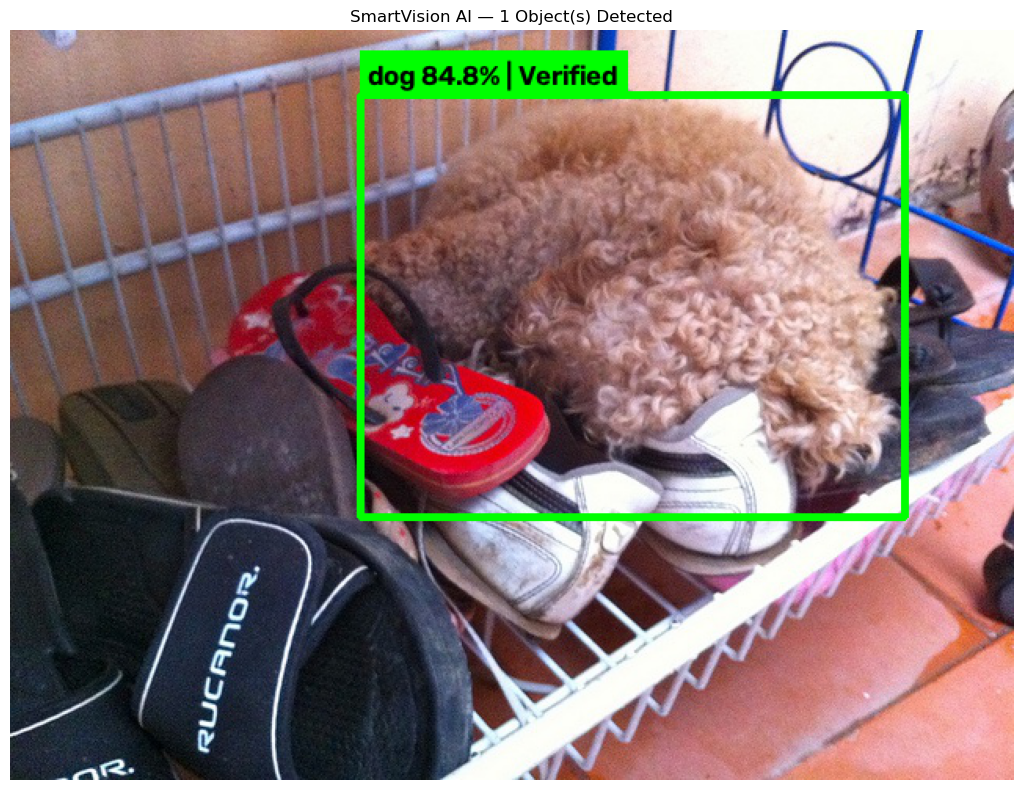


✅ Integrated detection visualization complete.


In [12]:
# ============================================================
# PHASE 4 - STEP 4.1
# CELL 7 - INTEGRATED PREDICTION VISUALIZATION
# ============================================================

def visualize_smartvision_prediction(
    prediction,
    show_resnet=True,
    save_path=None
):
    """
    Display SmartVision detections with:
    - Bounding boxes
    - YOLO class labels
    - YOLO confidence
    - Optional ResNet50 verification
    """

    # Convert PIL RGB image to NumPy array
    image = np.array(
        prediction["image"]
    ).copy()

    for detection in prediction["detections"]:

        x1, y1, x2, y2 = detection["bbox"]

        yolo_class = detection["yolo_class"]

        yolo_conf = (
            detection["yolo_confidence"] * 100
        )

        # ----------------------------------------------------
        # LABEL
        # ----------------------------------------------------

        label = (
            f"{yolo_class} "
            f"{yolo_conf:.1f}%"
        )

        # Add optional CNN verification
        if (
            show_resnet
            and detection["resnet_verification"]
            is not None
        ):

            resnet_result = detection[
                "resnet_verification"
            ]

            resnet_class = resnet_result[
                "predicted_class"
            ]

            resnet_conf = (
                resnet_result["confidence"] * 100
            )

            if detection["class_match"]:
                verification = "Verified"
            else:
                verification = (
                    f"CNN: {resnet_class} "
                    f"{resnet_conf:.1f}%"
                )

            label += f" | {verification}"

        # ----------------------------------------------------
        # DRAW BOUNDING BOX
        # ----------------------------------------------------

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        # Determine label size
        (text_width, text_height), baseline = (
            cv2.getTextSize(
                label,
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                2
            )
        )

        label_y1 = max(
            0,
            y1 - text_height - 12
        )

        # Label background
        cv2.rectangle(
            image,
            (x1, label_y1),
            (
                min(
                    image.shape[1],
                    x1 + text_width + 10
                ),
                y1
            ),
            (0, 255, 0),
            -1
        )

        # Label text
        cv2.putText(
            image,
            label,
            (x1 + 5, y1 - 6),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 0, 0),
            2,
            cv2.LINE_AA
        )

    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    plt.figure(figsize=(12, 8))

    plt.imshow(image)

    plt.title(
        f"SmartVision AI — "
        f"{prediction['number_of_detections']} "
        f"Object(s) Detected"
    )

    plt.axis("off")
    plt.tight_layout()

    # --------------------------------------------------------
    # OPTIONAL SAVE
    # --------------------------------------------------------

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight"
        )

        print(
            "Visualization saved to:"
        )
        print(save_path)

    plt.show()


# ------------------------------------------------------------
# VISUALIZE OUR CURRENT TEST RESULT
# ------------------------------------------------------------

integration_output_path = (
    RESULTS_DIR
    / "phase4_step4_1_integration_test.png"
)

visualize_smartvision_prediction(
    prediction,
    show_resnet=True,
    save_path=integration_output_path
)

print("\n✅ Integrated detection visualization complete.")

In [13]:
# ============================================================
# PHASE 4 - STEP 4.2
# CELL 8 - POST-PROCESSING CONFIGURATION
# ============================================================

# Final deployment thresholds
CONFIDENCE_THRESHOLD = 0.50
NMS_IOU_THRESHOLD = 0.70

print("=" * 70)
print("SMARTVISION AI - POST-PROCESSING CONFIGURATION")
print("=" * 70)

print(
    f"\nConfidence threshold : "
    f">{CONFIDENCE_THRESHOLD:.2f}"
)

print(
    f"NMS IoU threshold    : "
    f"{NMS_IOU_THRESHOLD:.2f}"
)

print("\nPost-processing pipeline:")
print("1. YOLO generates candidate detections")
print("2. Ultralytics applies NMS internally")
print("3. Overlapping duplicate boxes are suppressed")
print("4. Predictions with confidence <= 50% are removed")
print("5. Bounding boxes are clipped to image boundaries")
print("6. Class labels and confidence scores are formatted")
print("7. Optional ResNet50 verification is attached")

print(
    "\n✅ NMS is handled by YOLO/Ultralytics "
    "during model.predict()."
)

print(
    "✅ Final confidence filtering threshold "
    "set to >50%."
)

print(
    "✅ Step 4.2 post-processing "
    "configuration ready."
)

SMARTVISION AI - POST-PROCESSING CONFIGURATION

Confidence threshold : >0.50
NMS IoU threshold    : 0.70

Post-processing pipeline:
1. YOLO generates candidate detections
2. Ultralytics applies NMS internally
3. Overlapping duplicate boxes are suppressed
4. Predictions with confidence <= 50% are removed
5. Bounding boxes are clipped to image boundaries
6. Class labels and confidence scores are formatted
7. Optional ResNet50 verification is attached

✅ NMS is handled by YOLO/Ultralytics during model.predict().
✅ Final confidence filtering threshold set to >50%.
✅ Step 4.2 post-processing configuration ready.


In [14]:
# ============================================================
# PHASE 4 - STEP 4.2
# CELL 9 - FINAL POST-PROCESSED INFERENCE PIPELINE
# ============================================================

def smartvision_predict(
    image,
    confidence_threshold=CONFIDENCE_THRESHOLD,
    nms_iou_threshold=NMS_IOU_THRESHOLD,
    verify_with_resnet=True
):
    """
    Final SmartVision AI inference pipeline.

    Pipeline:
        Image
          ↓
        YOLOv8 detection
          ↓
        NMS (handled internally by Ultralytics)
          ↓
        Confidence filtering
          ↓
        Bounding-box refinement
          ↓
        Optional ResNet50 verification
          ↓
        Structured output
    """

    # --------------------------------------------------------
    # INPUT HANDLING
    # --------------------------------------------------------

    if isinstance(image, (str, Path)):
        pil_image = Image.open(image).convert("RGB")

    elif isinstance(image, Image.Image):
        pil_image = image.convert("RGB")

    else:
        raise TypeError(
            "image must be a file path or PIL Image."
        )

    image_width, image_height = pil_image.size


    # --------------------------------------------------------
    # YOLO DETECTION + NMS
    # --------------------------------------------------------

    # Use a low candidate threshold here.
    # Final >50% filtering is applied below.
    results = yolo_model.predict(
        source=np.array(pil_image),
        imgsz=640,
        conf=0.01,
        iou=nms_iou_threshold,
        device="cpu",
        verbose=False
    )

    result = results[0]

    detections = []


    # --------------------------------------------------------
    # POST-PROCESS DETECTIONS
    # --------------------------------------------------------

    if result.boxes is not None:

        for box in result.boxes:

            confidence = float(
                box.conf[0].item()
            )

            # Requirement: confidence >50%
            if confidence <= confidence_threshold:
                continue

            class_id = int(
                box.cls[0].item()
            )

            class_name = YOLO_CLASSES[
                class_id
            ]

            x1, y1, x2, y2 = (
                box.xyxy[0]
                .cpu()
                .tolist()
            )


            # ------------------------------------------------
            # REFINE / CLIP BOUNDING BOX
            # ------------------------------------------------

            x1 = max(
                0,
                min(
                    image_width,
                    int(round(x1))
                )
            )

            y1 = max(
                0,
                min(
                    image_height,
                    int(round(y1))
                )
            )

            x2 = max(
                0,
                min(
                    image_width,
                    int(round(x2))
                )
            )

            y2 = max(
                0,
                min(
                    image_height,
                    int(round(y2))
                )
            )

            # Remove invalid boxes
            if x2 <= x1 or y2 <= y1:
                continue


            # ------------------------------------------------
            # OBJECT CROP
            # ------------------------------------------------

            crop = pil_image.crop(
                (x1, y1, x2, y2)
            )


            # ------------------------------------------------
            # OPTIONAL CNN VERIFICATION
            # ------------------------------------------------

            resnet_result = None
            class_match = None

            if verify_with_resnet:

                resnet_result = (
                    classify_crop_with_resnet(
                        crop,
                        top_k=5
                    )
                )

                class_match = (
                    resnet_result[
                        "predicted_class"
                    ]
                    == class_name
                )


            # ------------------------------------------------
            # FORMAT DISPLAY LABEL
            # ------------------------------------------------

            display_label = (
                f"{class_name} "
                f"{confidence * 100:.1f}%"
            )

            if verify_with_resnet:

                if class_match:

                    display_label += (
                        " | Verified"
                    )

                else:

                    cnn_class = resnet_result[
                        "predicted_class"
                    ]

                    cnn_conf = resnet_result[
                        "confidence"
                    ]

                    display_label += (
                        f" | CNN: "
                        f"{cnn_class} "
                        f"{cnn_conf * 100:.1f}%"
                    )


            # ------------------------------------------------
            # STORE FINAL DETECTION
            # ------------------------------------------------

            detections.append({

                "class_id":
                    class_id,

                "class_name":
                    class_name,

                "confidence":
                    confidence,

                "bbox":
                    [x1, y1, x2, y2],

                "display_label":
                    display_label,

                "resnet_verification":
                    resnet_result,

                "class_match":
                    class_match
            })


    # Sort strongest detections first
    detections.sort(
        key=lambda x: x["confidence"],
        reverse=True
    )


    # --------------------------------------------------------
    # FINAL OUTPUT
    # --------------------------------------------------------

    return {

        "image":
            pil_image,

        "image_size": {
            "width": image_width,
            "height": image_height
        },

        "confidence_threshold":
            confidence_threshold,

        "nms_iou_threshold":
            nms_iou_threshold,

        "resnet_verification_enabled":
            verify_with_resnet,

        "number_of_detections":
            len(detections),

        "detections":
            detections
    }


print("✅ Final post-processed SmartVision pipeline created.")
print(f"Default confidence threshold: >{CONFIDENCE_THRESHOLD:.2f}")
print(f"Default NMS IoU threshold   : {NMS_IOU_THRESHOLD:.2f}")
print("✅ Bounding-box clipping enabled.")
print("✅ Detection labels formatted.")
print("✅ Optional ResNet50 verification enabled.")

✅ Final post-processed SmartVision pipeline created.
Default confidence threshold: >0.50
Default NMS IoU threshold   : 0.70
✅ Bounding-box clipping enabled.
✅ Detection labels formatted.
✅ Optional ResNet50 verification enabled.


In [15]:
# ============================================================
# PHASE 4 - STEP 4.2
# CELL 10 - MULTI-OBJECT POST-PROCESSING TEST
# ============================================================

print("=" * 70)
print("SEARCHING FOR MULTI-OBJECT TEST IMAGE")
print("=" * 70)

multi_prediction = None
multi_image_path = None

# Search test images until we find >= 3 final detections
for i, image_path in enumerate(test_images, start=1):

    result = smartvision_predict(
        image_path,
        confidence_threshold=0.50,
        nms_iou_threshold=0.70,

        # Disable CNN while searching to make this faster
        verify_with_resnet=False
    )

    if result["number_of_detections"] >= 3:

        multi_image_path = image_path
        break

    if i % 50 == 0:
        print(f"Checked {i}/{len(test_images)} images...")


assert multi_image_path is not None, \
    "No image with at least 3 detections was found."


# ------------------------------------------------------------
# RUN AGAIN WITH RESNET VERIFICATION ENABLED
# ------------------------------------------------------------

multi_prediction = smartvision_predict(
    multi_image_path,
    confidence_threshold=0.50,
    nms_iou_threshold=0.70,
    verify_with_resnet=True
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\nMulti-object image:")
print(multi_image_path)

print(
    "\nFinal detections:",
    multi_prediction["number_of_detections"]
)

print(
    "Confidence threshold:",
    multi_prediction["confidence_threshold"]
)

print(
    "NMS IoU threshold:",
    multi_prediction["nms_iou_threshold"]
)


for i, det in enumerate(
    multi_prediction["detections"],
    start=1
):

    print("\n" + "-" * 60)

    print(
        f"{i}. {det['display_label']}"
    )

    print(
        "   Bounding box:",
        det["bbox"]
    )


print("\n" + "=" * 70)
print("✅ MULTI-OBJECT POST-PROCESSING TEST COMPLETE")
print("=" * 70)

SEARCHING FOR MULTI-OBJECT TEST IMAGE

Multi-object image:
E:\SmartVision-AI\data\optimized_detection_v2\images\test\coco_000035.jpg

Final detections: 4
Confidence threshold: 0.5
NMS IoU threshold: 0.7

------------------------------------------------------------
1. person 93.0% | Verified
   Bounding box: [270, 182, 376, 418]

------------------------------------------------------------
2. person 92.6% | Verified
   Bounding box: [350, 255, 481, 480]

------------------------------------------------------------
3. person 84.0% | Verified
   Bounding box: [436, 216, 516, 463]

------------------------------------------------------------
4. person 68.0% | Verified
   Bounding box: [0, 268, 38, 480]

✅ MULTI-OBJECT POST-PROCESSING TEST COMPLETE


Saved to:
E:\SmartVision-AI\results\integration\phase4_step4_2_multi_object_test.png


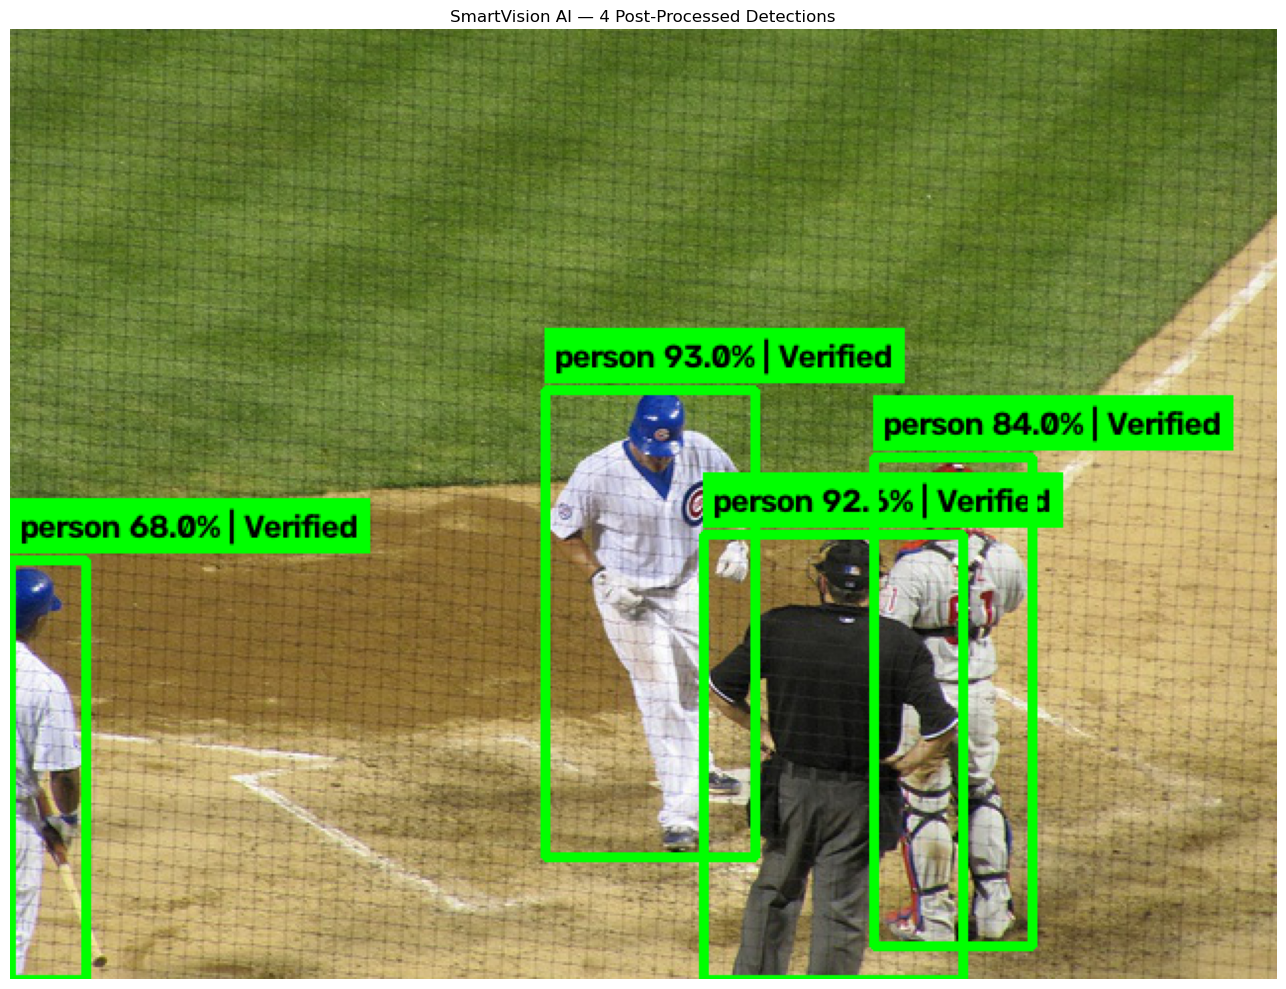


Final detections: 4
Confidence filter: > 0.5
NMS IoU: 0.7

✅ Step 4.2 visualization complete.


In [16]:
# ============================================================
# PHASE 4 - STEP 4.2
# CELL 11 - FINAL MULTI-OBJECT VISUALIZATION
# ============================================================

def visualize_final_prediction(
    prediction,
    save_path=None
):
    """
    Visualize final post-processed SmartVision detections.
    """

    image = np.array(
        prediction["image"]
    ).copy()

    # --------------------------------------------------------
    # DRAW EACH DETECTION
    # --------------------------------------------------------

    for det in prediction["detections"]:

        x1, y1, x2, y2 = det["bbox"]

        label = det["display_label"]

        # Bounding box
        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        # Calculate text size
        (text_width, text_height), baseline = (
            cv2.getTextSize(
                label,
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                2
            )
        )

        # Keep label inside image
        text_y = max(
            text_height + 8,
            y1 - 8
        )

        background_top = max(
            0,
            text_y - text_height - 8
        )

        background_right = min(
            image.shape[1],
            x1 + text_width + 10
        )

        # Label background
        cv2.rectangle(
            image,
            (x1, background_top),
            (background_right, text_y + 4),
            (0, 255, 0),
            -1
        )

        # Label
        cv2.putText(
            image,
            label,
            (x1 + 5, text_y - 3),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 0, 0),
            2,
            cv2.LINE_AA
        )

    # --------------------------------------------------------
    # DISPLAY
    # --------------------------------------------------------

    plt.figure(figsize=(14, 10))

    plt.imshow(image)

    plt.title(
        "SmartVision AI — "
        f"{prediction['number_of_detections']} "
        "Post-Processed Detections"
    )

    plt.axis("off")
    plt.tight_layout()

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=200,
            bbox_inches="tight"
        )

        print("Saved to:")
        print(save_path)

    plt.show()


# ------------------------------------------------------------
# SAVE MULTI-OBJECT RESULT
# ------------------------------------------------------------

multi_output_path = (
    RESULTS_DIR
    / "phase4_step4_2_multi_object_test.png"
)

visualize_final_prediction(
    multi_prediction,
    save_path=multi_output_path
)

print("\nFinal detections:",
      multi_prediction["number_of_detections"])

print(
    "Confidence filter: >",
    multi_prediction["confidence_threshold"]
)

print(
    "NMS IoU:",
    multi_prediction["nms_iou_threshold"]
)

print("\n✅ Step 4.2 visualization complete.")

In [17]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 12 - RESNET50 DYNAMIC QUANTIZATION
# ============================================================

import copy
import time

print("=" * 70)
print("RESNET50 DYNAMIC QUANTIZATION")
print("=" * 70)

# Keep original final model untouched
resnet_cpu = copy.deepcopy(
    resnet_model
).to("cpu").eval()

# Dynamic INT8 quantization
# Quantizes supported Linear layers while preserving
# the original trained checkpoint.
quantized_resnet = torch.ao.quantization.quantize_dynamic(
    resnet_cpu,
    {nn.Linear},
    dtype=torch.qint8
)

quantized_resnet.eval()

print("\nOriginal model:")
print("Final ResNet50 FP32")

print("\nOptimized model:")
print("Dynamic INT8 quantization applied to Linear layers")

print("\nOriginal checkpoint remains unchanged:")
print(RESNET_MODEL_PATH)

print("\nQuantized layers:")

quantized_count = 0

for name, module in quantized_resnet.named_modules():

    if "quantized.dynamic" in str(type(module)):

        print(" -", name)

        quantized_count += 1

print(
    "\nNumber of dynamically quantized modules:",
    quantized_count
)

print("\n✅ ResNet50 quantization created successfully.")
print("✅ Original final model remains untouched.")

RESNET50 DYNAMIC QUANTIZATION

Original model:
Final ResNet50 FP32

Optimized model:
Dynamic INT8 quantization applied to Linear layers

Original checkpoint remains unchanged:
E:\SmartVision-AI\models\resnet50_final_best.pth

Quantized layers:
 - fc.0
 - fc.3

Number of dynamically quantized modules: 2

✅ ResNet50 quantization created successfully.
✅ Original final model remains untouched.


C:\Users\athiy\AppData\Local\Temp\ipykernel_12940\3157008584.py:21: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quantized_resnet = torch.ao.quantization.quantize_dynamic(


In [18]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 13 - VALIDATE FP32 VS QUANTIZED RESNET50
# ============================================================

# Use the first detection from our successful test image
test_detection = prediction["detections"][0]

x1, y1, x2, y2 = test_detection["bbox"]

test_crop = prediction["image"].crop(
    (x1, y1, x2, y2)
).convert("RGB")

# Preprocess
input_tensor = (
    resnet_transform(test_crop)
    .unsqueeze(0)
    .to("cpu")
)


# ------------------------------------------------------------
# ORIGINAL FP32 MODEL
# ------------------------------------------------------------

resnet_cpu.eval()

with torch.inference_mode():

    fp32_output = resnet_cpu(
        input_tensor
    )

    fp32_probs = torch.softmax(
        fp32_output,
        dim=1
    )[0]

fp32_idx = int(
    torch.argmax(fp32_probs)
)

fp32_class = RESNET_CLASSES[
    fp32_idx
]

fp32_conf = float(
    fp32_probs[fp32_idx]
)


# ------------------------------------------------------------
# QUANTIZED MODEL
# ------------------------------------------------------------

quantized_resnet.eval()

with torch.inference_mode():

    int8_output = quantized_resnet(
        input_tensor
    )

    int8_probs = torch.softmax(
        int8_output,
        dim=1
    )[0]

int8_idx = int(
    torch.argmax(int8_probs)
)

int8_class = RESNET_CLASSES[
    int8_idx
]

int8_conf = float(
    int8_probs[int8_idx]
)


# ------------------------------------------------------------
# COMPARISON
# ------------------------------------------------------------

print("=" * 70)
print("FP32 VS DYNAMIC INT8 VALIDATION")
print("=" * 70)

print("\nOriginal FP32:")
print(
    f"Prediction : {fp32_class}"
)
print(
    f"Confidence : {fp32_conf * 100:.2f}%"
)

print("\nQuantized INT8:")
print(
    f"Prediction : {int8_class}"
)
print(
    f"Confidence : {int8_conf * 100:.2f}%"
)

print(
    "\nSame predicted class:",
    fp32_class == int8_class
)

print(
    "Confidence difference:",
    f"{abs(fp32_conf - int8_conf) * 100:.2f} percentage points"
)

print("\n✅ Quantized model validation complete.")

FP32 VS DYNAMIC INT8 VALIDATION

Original FP32:
Prediction : dog
Confidence : 90.23%

Quantized INT8:
Prediction : dog
Confidence : 90.14%

Same predicted class: True
Confidence difference: 0.09 percentage points

✅ Quantized model validation complete.


In [19]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 14 - FP32 VS INT8 CPU INFERENCE BENCHMARK
# ============================================================

import time

WARMUP_RUNS = 10
BENCHMARK_RUNS = 50


def benchmark_model(model, input_tensor, runs=50, warmups=10):
    """
    Measure average CPU inference latency.
    """

    model.eval()

    # Warm-up
    with torch.inference_mode():

        for _ in range(warmups):
            _ = model(input_tensor)

    # Benchmark
    start = time.perf_counter()

    with torch.inference_mode():

        for _ in range(runs):
            _ = model(input_tensor)

    end = time.perf_counter()

    total_time = end - start

    avg_ms = (
        total_time / runs
    ) * 1000

    fps = (
        1000 / avg_ms
        if avg_ms > 0
        else 0
    )

    return avg_ms, fps


print("=" * 70)
print("RESNET50 CPU INFERENCE BENCHMARK")
print("=" * 70)

# ------------------------------------------------------------
# FP32
# ------------------------------------------------------------

fp32_ms, fp32_fps = benchmark_model(
    resnet_cpu,
    input_tensor,
    runs=BENCHMARK_RUNS,
    warmups=WARMUP_RUNS
)

# ------------------------------------------------------------
# INT8
# ------------------------------------------------------------

int8_ms, int8_fps = benchmark_model(
    quantized_resnet,
    input_tensor,
    runs=BENCHMARK_RUNS,
    warmups=WARMUP_RUNS
)

# ------------------------------------------------------------
# SPEEDUP
# ------------------------------------------------------------

speedup = (
    fp32_ms / int8_ms
    if int8_ms > 0
    else 0
)

latency_reduction = (
    (fp32_ms - int8_ms)
    / fp32_ms
    * 100
)

print("\nFP32 ResNet50")
print(f"Latency : {fp32_ms:.2f} ms/image")
print(f"FPS     : {fp32_fps:.2f}")

print("\nDynamic INT8 ResNet50")
print(f"Latency : {int8_ms:.2f} ms/image")
print(f"FPS     : {int8_fps:.2f}")

print("\nOptimization")
print(f"Speedup           : {speedup:.2f}x")
print(
    f"Latency reduction : "
    f"{latency_reduction:.2f}%"
)

print(
    "\nPrediction preserved:",
    fp32_class == int8_class
)

print("\n✅ Quantization benchmark complete.")

RESNET50 CPU INFERENCE BENCHMARK

FP32 ResNet50
Latency : 87.41 ms/image
FPS     : 11.44

Dynamic INT8 ResNet50
Latency : 91.15 ms/image
FPS     : 10.97

Optimization
Speedup           : 0.96x
Latency reduction : -4.28%

Prediction preserved: True

✅ Quantization benchmark complete.


In [20]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 15 - MULTI-IMAGE BATCH PROCESSING
# ============================================================

def smartvision_batch_predict(
    images,
    confidence_threshold=0.50,
    nms_iou_threshold=0.70,
    verify_with_resnet=False
):
    """
    Process multiple images using the SmartVision pipeline.

    Parameters
    ----------
    images : list
        List of image paths or PIL Images.

    confidence_threshold : float
        Final YOLO confidence threshold.

    nms_iou_threshold : float
        YOLO NMS IoU threshold.

    verify_with_resnet : bool
        Enable optional ResNet50 verification.

    Returns
    -------
    list
        Prediction dictionary for each image.
    """

    batch_results = []

    start_time = time.perf_counter()

    for index, image in enumerate(images, start=1):

        result = smartvision_predict(
            image=image,
            confidence_threshold=confidence_threshold,
            nms_iou_threshold=nms_iou_threshold,
            verify_with_resnet=verify_with_resnet
        )

        batch_results.append(result)

        print(
            f"Processed {index}/{len(images)} "
            f"| detections: "
            f"{result['number_of_detections']}"
        )

    total_time = (
        time.perf_counter() - start_time
    )

    avg_time = (
        total_time / len(images)
        if images
        else 0
    )

    print("\n" + "=" * 70)
    print("BATCH PROCESSING COMPLETE")
    print("=" * 70)

    print(
        f"Images processed : {len(images)}"
    )

    print(
        f"Total time       : {total_time:.2f} sec"
    )

    print(
        f"Average time     : "
        f"{avg_time * 1000:.2f} ms/image"
    )

    return batch_results


print("✅ SmartVision batch-processing function created.")
print("✅ Supports multiple images.")
print("✅ Confidence and NMS thresholds configurable.")
print("✅ Optional ResNet50 verification supported.")

✅ SmartVision batch-processing function created.
✅ Supports multiple images.
✅ Confidence and NMS thresholds configurable.
✅ Optional ResNet50 verification supported.


In [21]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 16 - TEST MULTI-IMAGE BATCH PROCESSING
# ============================================================

# Select 5 test images
batch_test_images = test_images[:5]

print("=" * 70)
print("SMARTVISION BATCH PROCESSING TEST")
print("=" * 70)

print("\nImages selected:", len(batch_test_images))

for path in batch_test_images:
    print(" -", path.name)


# ------------------------------------------------------------
# RUN BATCH
# ------------------------------------------------------------

batch_predictions = smartvision_batch_predict(
    images=batch_test_images,
    confidence_threshold=0.50,
    nms_iou_threshold=0.70,
    verify_with_resnet=False
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

total_detections = sum(
    result["number_of_detections"]
    for result in batch_predictions
)

print("\nDetection summary:")

for image_path, result in zip(
    batch_test_images,
    batch_predictions
):

    print(
        f"{image_path.name}: "
        f"{result['number_of_detections']} object(s)"
    )

print(
    "\nTotal objects detected:",
    total_detections
)

print(
    "\n✅ Multi-image batch processing verified."
)

SMARTVISION BATCH PROCESSING TEST

Images selected: 5
 - coco_000005.jpg
 - coco_000013.jpg
 - coco_000015.jpg
 - coco_000018.jpg
 - coco_000024.jpg
Processed 1/5 | detections: 1
Processed 2/5 | detections: 2
Processed 3/5 | detections: 1
Processed 4/5 | detections: 0
Processed 5/5 | detections: 1

BATCH PROCESSING COMPLETE
Images processed : 5
Total time       : 0.67 sec
Average time     : 134.16 ms/image

Detection summary:
coco_000005.jpg: 1 object(s)
coco_000013.jpg: 2 object(s)
coco_000015.jpg: 1 object(s)
coco_000018.jpg: 0 object(s)
coco_000024.jpg: 1 object(s)

Total objects detected: 5

✅ Multi-image batch processing verified.


In [22]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 17 - SAFE GPU ACCELERATION CONFIGURATION CHECK
# ============================================================

print("=" * 70)
print("SMARTVISION GPU ACCELERATION CONFIGURATION")
print("=" * 70)

# ------------------------------------------------------------
# CUDA AVAILABILITY
# ------------------------------------------------------------

cuda_available = torch.cuda.is_available()

print("\nCUDA available:", cuda_available)

if cuda_available:

    gpu_count = torch.cuda.device_count()

    print("CUDA devices:", gpu_count)

    # Query device information only
    gpu_name = torch.cuda.get_device_name(0)

    print("GPU:", gpu_name)

    GPU_DEVICE = "cuda:0"

    print("\nConfigured GPU device:", GPU_DEVICE)

else:

    GPU_DEVICE = "cpu"

    print("\nCUDA unavailable.")
    print("Configured fallback device:", GPU_DEVICE)


# ------------------------------------------------------------
# DEPLOYMENT DEVICE SELECTION
# ------------------------------------------------------------

def get_inference_device(prefer_gpu=True):
    """
    Select GPU when available and requested.
    Otherwise safely fall back to CPU.
    """

    if prefer_gpu and torch.cuda.is_available():
        return "cuda:0"

    return "cpu"


configured_device = get_inference_device(
    prefer_gpu=True
)

print(
    "\nAutomatic inference device:",
    configured_device
)

print("\nGPU acceleration strategy:")
print("• Local CUDA GPU → use cuda:0")
print("• CPU-only/cloud environment → automatically use CPU")
print("• Models are loaded only on the selected device")
print("• GPU memory is not allocated by this configuration cell")

print(
    "\n✅ GPU-aware inference configuration created."
)

SMARTVISION GPU ACCELERATION CONFIGURATION

CUDA available: True
CUDA devices: 1
GPU: NVIDIA GeForce RTX 4050 Laptop GPU

Configured GPU device: cuda:0

Automatic inference device: cuda:0

GPU acceleration strategy:
• Local CUDA GPU → use cuda:0
• CPU-only/cloud environment → automatically use CPU
• Models are loaded only on the selected device
• GPU memory is not allocated by this configuration cell

✅ GPU-aware inference configuration created.


In [23]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 18 - SAFE GPU INFERENCE TEST
# ============================================================

import time

print("=" * 70)
print("YOLO GPU ACCELERATION TEST")
print("=" * 70)

gpu_test_image = test_images[0]

print("\nTest image:")
print(gpu_test_image.name)

print("\nRunning ONE YOLO inference on RTX 4050...")

start = time.perf_counter()

gpu_result = yolo_model.predict(
    source=str(gpu_test_image),
    imgsz=640,
    conf=0.50,
    iou=0.70,
    device=0,          # RTX 4050
    verbose=False
)[0]

elapsed_ms = (
    time.perf_counter() - start
) * 1000

detections = (
    len(gpu_result.boxes)
    if gpu_result.boxes is not None
    else 0
)

print("\n✅ GPU inference successful")

print("Device     : NVIDIA RTX 4050")
print("Detections :", detections)

print(
    f"Total call time : "
    f"{elapsed_ms:.2f} ms"
)

# Ultralytics model-only timing
if hasattr(gpu_result, "speed"):

    print("\nUltralytics timing:")

    print(
        f"Preprocess  : "
        f"{gpu_result.speed['preprocess']:.2f} ms"
    )

    print(
        f"Inference   : "
        f"{gpu_result.speed['inference']:.2f} ms"
    )

    print(
        f"Postprocess : "
        f"{gpu_result.speed['postprocess']:.2f} ms"
    )

print(
    "\nAllocated GPU memory:",
    f"{torch.cuda.memory_allocated(0) / 1024**3:.2f} GB"
)

print(
    "Reserved GPU memory :",
    f"{torch.cuda.memory_reserved(0) / 1024**3:.2f} GB"
)

print("\n✅ GPU acceleration verified.")

YOLO GPU ACCELERATION TEST

Test image:
coco_000005.jpg

Running ONE YOLO inference on RTX 4050...

✅ GPU inference successful
Device     : NVIDIA RTX 4050
Detections : 1
Total call time : 1972.03 ms

Ultralytics timing:
Preprocess  : 85.23 ms
Inference   : 9.15 ms
Postprocess : 30.99 ms

Allocated GPU memory: 0.04 GB
Reserved GPU memory : 0.08 GB

✅ GPU acceleration verified.


In [24]:
# ============================================================
# PHASE 4 - STEP 4.3
# CELL 19 - CLOUD / MEMORY OPTIMIZATION CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# DEPLOYMENT CONFIGURATION
# ------------------------------------------------------------

DEPLOYMENT_CONFIG = {

    # Detection
    "image_size": 640,
    "confidence_threshold": 0.50,
    "nms_iou_threshold": 0.70,

    # Memory-conscious defaults
    "batch_size": 1,

    # CNN verification is optional because running a second
    # model for every detection increases CPU/RAM usage.
    "resnet_verification_default": False,

    # Device fallback
    "prefer_gpu": True,
    "cpu_fallback": True,

    # Use inference-only execution
    "use_inference_mode": True,

    # Process uploaded images sequentially rather than
    # retaining unnecessary prediction tensors.
    "sequential_processing": True
}


# ------------------------------------------------------------
# MEMORY CLEANUP HELPER
# ------------------------------------------------------------

def release_inference_memory():
    """
    Release temporary Python/CUDA inference memory.
    Safe for CPU-only environments as well.
    """

    import gc

    gc.collect()

    if torch.cuda.is_available():

        try:
            torch.cuda.empty_cache()

        except Exception:
            # Cloud/CPU environments should continue safely
            pass


# ------------------------------------------------------------
# DISPLAY CONFIGURATION
# ------------------------------------------------------------

print("=" * 70)
print("SMARTVISION CLOUD DEPLOYMENT OPTIMIZATION")
print("=" * 70)

for key, value in DEPLOYMENT_CONFIG.items():

    print(
        f"{key:<32}: {value}"
    )


print("\nMemory optimization strategy:")

print("• Load each trained model once and reuse it")
print("• Use torch.inference_mode() during prediction")
print("• Default deployment batch size = 1")
print("• Resize YOLO inference input to 640")
print("• Avoid retaining unnecessary prediction tensors")
print("• Process multiple uploads sequentially when memory is limited")
print("• Keep ResNet verification optional")
print("• Automatically fall back to CPU when CUDA is unavailable")
print("• Explicit cleanup helper available after large inference jobs")

print("\nDeployment model decisions:")

print("YOLOv8s        : Keep final trained model")
print("ResNet50 FP32  : Keep as primary classifier")
print(
    "ResNet50 INT8  : Tested, but not selected "
    "(slower on current CPU)"
)

print("\n✅ Cloud memory optimization configuration ready.")
print("✅ Step 4.3 performance optimization complete.")

SMARTVISION CLOUD DEPLOYMENT OPTIMIZATION
image_size                      : 640
confidence_threshold            : 0.5
nms_iou_threshold               : 0.7
batch_size                      : 1
resnet_verification_default     : False
prefer_gpu                      : True
cpu_fallback                    : True
use_inference_mode              : True
sequential_processing           : True

Memory optimization strategy:
• Load each trained model once and reuse it
• Use torch.inference_mode() during prediction
• Default deployment batch size = 1
• Resize YOLO inference input to 640
• Avoid retaining unnecessary prediction tensors
• Process multiple uploads sequentially when memory is limited
• Keep ResNet verification optional
• Automatically fall back to CPU when CUDA is unavailable
• Explicit cleanup helper available after large inference jobs

Deployment model decisions:
YOLOv8s        : Keep final trained model
ResNet50 FP32  : Keep as primary classifier
ResNet50 INT8  : Tested, but not 